In [7]:
from joblib import Parallel, delayed

from matplotlib.figure import Figure
from tqdm import tqdm
import matplotlib.pyplot as plt
import numpy as np
import ququart_analytical as an
import experimental as ex




alpha_space = np.linspace(0.501, 0.999, 50)

def scan_parallel(func):
    return Parallel(n_jobs=-2)(
        delayed(an.scan_analytical)(alpha, func, iters=100) for alpha in tqdm(alpha_space, leave=True)
    )

best_gaps = scan_parallel(an.full_swap)

100%|██████████| 50/50 [00:08<00:00,  6.03it/s]


In [8]:
def scan_experimental(alpha_goal):
    energies = ex.scan_gaps(4, alpha_goal, iters=60, gap_min=0.001, gap_max=100)
    _, _, _, e_values, _ = zip(*energies)
    min_gaps = energies[np.argmin(e_values)]
    return alpha_goal, *min_gaps


best_gaps_exp = Parallel(n_jobs=-2)(
    delayed(scan_experimental)(alpha) for alpha in tqdm(alpha_space, leave=True)
)

100%|██████████| 50/50 [02:28<00:00,  2.97s/it]


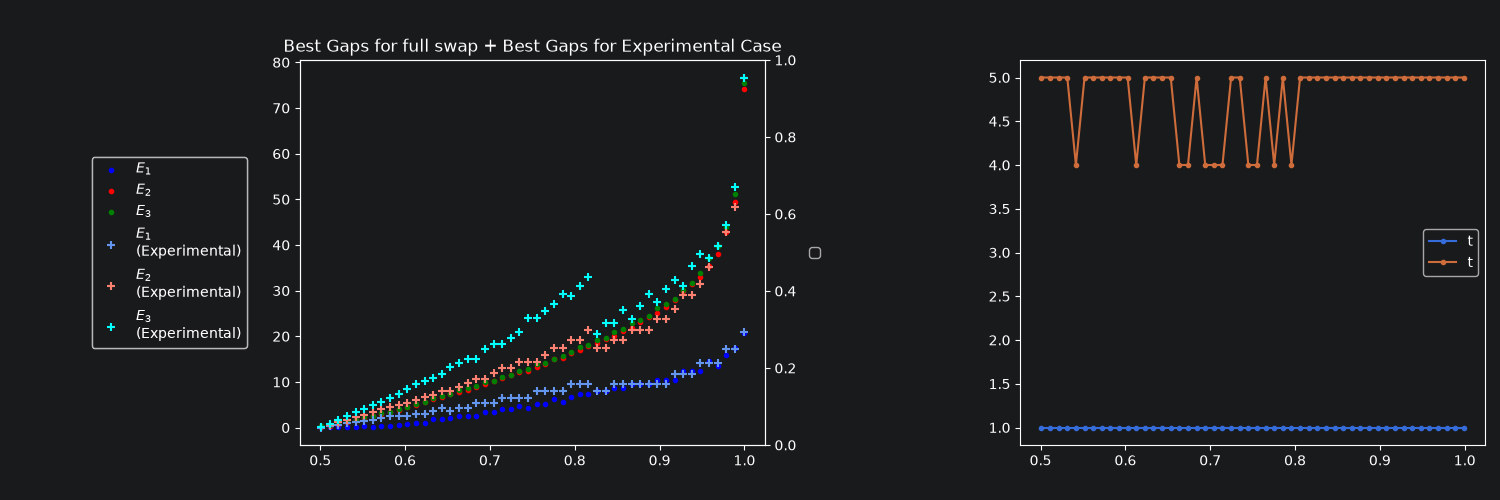

In [9]:
from types import MappingProxyType
%config InlineBackend.print_figure_kwargs = {'bbox_inches': None}


colourmap_analytical = MappingProxyType({"E1": ("cyan", "blue"), "E2": ("pink", "red"), "E3": ("green", "green"), "ratio": ("olive", "orange")})
colourmap_experimental = MappingProxyType({"E1": ("paleturquoise", "cornflowerblue"), "E2": ("thistle", "salmon"), "E3": ("aqua", "aqua"), "ratio": ("wheat", "yellow")})


def plot_best_gaps(best_gaps: list[tuple[float, float, float, float, float]], title: str, fig=None, markers='.',
                   colourmap: MappingProxyType[str, str | tuple[str, str]] = colourmap_analytical, suffix="") -> Figure:
    alphas, gap1s, gap2s, gap3s, energies, t = zip(*best_gaps)
    idx = np.isfinite(gap1s)
    alphas, gap1s, gap2s, gap3s, energies, t = zip(*np.array(best_gaps)[idx])

    ax, axt, ax2 = None, None, None
    energy_handles, ratio_handles = [], []

    if fig is None:
        fig, (ax, axt) = plt.subplots(1, 2, figsize=(15, 5))
    else:
        (ax, axt, ax2) = fig.get_axes()
        energy_handles, _ = ax.get_legend_handles_labels()
        ax.get_legend().remove()
        ratio_handles, _ = ax2.get_legend_handles_labels()
        ax2.get_legend().remove()

    #ax.set_yscale("log")
    e1r = ax.scatter(alphas, gap1s, marker=markers, label=r"$E_1$" + suffix, color=colourmap["E1"][1], zorder=5)
    e2r = ax.scatter(alphas, np.array(gap2s) + np.array(gap1s), marker=markers, label=r"$E_2$" + suffix, color=colourmap["E2"][1], zorder=5)
    e3r = ax.scatter(alphas, np.array(gap3s) + np.array(gap2s) + np.array(gap1s), marker=markers, label=r"$E_3$" + suffix, color=colourmap["E3"][1], zorder=5)
    energy_handles.extend([e1r, e2r, e3r])

    if ax2 is None:
        ax2 = ax.twinx()
    gap_ratio = np.array(gap2s) / np.array(gap1s)
    poly = np.polynomial.polynomial.Polynomial.fit(alphas[2:], gap_ratio[2:], 3)
    #r = ax2.scatter(alphas[2:], gap_ratio[2:], marker=markers, label="$\\dfrac{E_2-E_1}{E_1}$" + suffix, color=colourmap["ratio"][1], zorder=5)
    #rfit, = ax2.plot(alphas[2:], poly(alphas[2:]), label="$\\dfrac{E_2-E_1}{E_1}$\n(best fit)" + suffix, color=colourmap["ratio"][0])
    #ratio_handles.extend([rfit, r])

    curr_tit = ax.get_title()
    ax.set_title(curr_tit + (" + " if len(curr_tit) != 0 else "") + title)

    leg1 = ax.legend(handles=energy_handles, loc='center right', bbox_to_anchor=(-0.1, 0.5))
    ax.add_artist(leg1)

    ax2.legend(handles=ratio_handles, loc='center left', bbox_to_anchor=(1.08, 0.5))

    axt.plot(alphas, t, marker='.', label=r"t")
    axt.legend()
    plt.subplots_adjust(left=0.2, right=0.99, wspace=0.55)
    return fig


fig = plot_best_gaps(best_gaps, "Best Gaps for full swap")
plot_best_gaps(best_gaps_exp, "Best Gaps for Experimental Case", fig=fig, markers='+', colourmap=colourmap_experimental, suffix="\n(Experimental)")
plt.show()


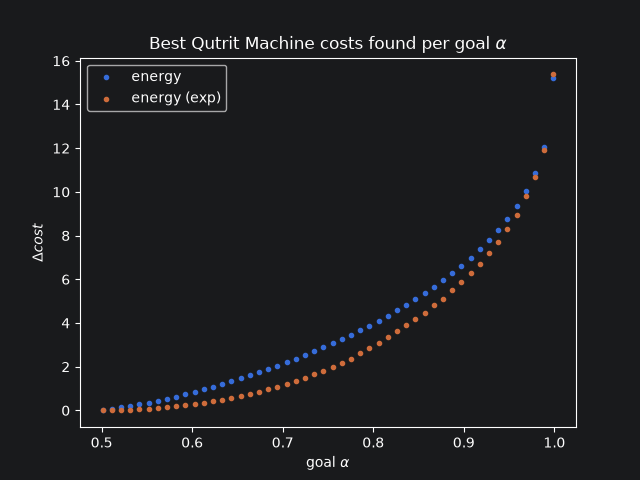

In [10]:
alphas, _, _, _, energies, _ = zip(*best_gaps)
alphase, _, _, _, energiese, _ = zip(*best_gaps_exp)

ax = plt.gca()
#ax.set_yscale('log')
ax.scatter(alphas, energies, marker='.', label=r"energy")
ax.scatter(alphase, energiese, marker='.', label=r"energy (exp)")

ax.set_ylabel(r"$\Delta cost$")
ax.set_xlabel(r"goal $\alpha$")
plt.title(r'Best Qutrit Machine costs found per goal $\alpha$')
ax.legend()

plt.show()